# NYSE 收盘竞价预测：数据与模型结果

这个 Notebook 展示 NYSE 建模数据、按日期留出的测试结果、按季度扩展训练的回测，以及按季度更新的 K-means 股票分组对照。数据来自现有 WRDS TAQ 与 Bloomberg 文件；处理脚本不下载新数据，也不改动 raw 文件。

处理脚本：`modeling/prepare_nyse_model.py`  
生成文件：`Data/processed/nyse/`

In [ ]:
from pathlib import Path
import os
import sys
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the repository by its model script so the notebook works from a checkout.
_here = Path.cwd().resolve()
_candidates = [_here, *_here.parents]
WORKSPACE = next((p for p in _candidates if (p / "modeling/prepare_nyse_model.py").is_file()), None)
if WORKSPACE is None:
    raise FileNotFoundError("Could not find modeling/prepare_nyse_model.py above the current directory.")

_local_project = WORKSPACE / "Eqiuty-Closing-Auction-2026-Yiying"
_default_project = _local_project if _local_project.is_dir() else WORKSPACE
PROJECT = Path(os.environ.get("NYSE_PROJECT_DIR", _default_project)).resolve()
OUTPUT = PROJECT / "Data/processed/nyse"
SCRIPT = WORKSPACE / "modeling/prepare_nyse_model.py"
required_files = [
    OUTPUT / "nyse_model_panel.csv.gz",
    OUTPUT / "nyse_test_predictions.csv.gz",
    OUTPUT / "nyse_model_metrics.csv",
    OUTPUT / "nyse_data_audit.csv",
]

# Set True to rebuild from local TAQ, Bloomberg, and reference-calendar inputs.
RUN_PIPELINE = False
if RUN_PIPELINE:
    subprocess.run([sys.executable, str(SCRIPT), "--project-dir", str(PROJECT)], check=True)
missing_outputs = [str(path) for path in required_files if not path.exists()]
if missing_outputs:
    raise FileNotFoundError(
        "Processed NYSE outputs are missing. Set RUN_PIPELINE=True after placing the required local inputs under the project Data/ folder."
    )

print("Repository:", WORKSPACE)
print("Project data root:", PROJECT)
print("Output folder:", OUTPUT)


## 数据覆盖和缺失标签

建模表的每一行是一只股票在它现有数据期间的一个交易日。没有 TAQ condition 6 成交记录的 auction 标签保留为空，不填成 0。本节展示总体覆盖情况，以及每只股票在自己有数据的日期中缺少多少标签。

In [2]:
quality = pd.read_csv(OUTPUT / "nyse_data_audit.csv")
metrics = pd.read_csv(OUTPUT / "nyse_model_metrics.csv")

panel_columns = [
    "date", "ticker", "auction_volume", "target_missing_reason", "sample_split",
    "cumvol_10:00", "cumvol_12:00", "cumvol_14:00", "cumvol_15:00", "cumvol_15:30", "cumvol_15:50",
    "feat_px_last_log", "feat_return_1d", "feat_momentum_5d", "feat_momentum_20d",
    "feat_volatility_20d", "feat_volatility_60d",
    "feat_market_cap_log", "feat_px_volume_log1p", "feat_turnover_log1p",
    "feat_px_last_was_asof_filled", "feat_market_cap_was_asof_filled",
    "feat_px_volume_was_rolling_filled", "feat_turnover_was_rolling_filled",
]
panel = pd.read_csv(OUTPUT / "nyse_model_panel.csv.gz", compression="gzip", usecols=panel_columns, low_memory=False)
panel["date"] = pd.to_datetime(panel["date"])

pred_columns = [
    "ticker", "date", "actual_auction_volume", "auction_persistence", "auction_ridge",
    "auction_ridge_target_winsor_sens", "auction_ridge_KMeans_expanding",
    "quarterly_kmeans_cluster", "quarterly_kmeans_selected_k", "XGBoost_preopen", "LightGBM_preopen",
    "CatBoost_preopen", "HistGradientBoosting_preopen",
]
for cp in ["1000", "1200", "1400", "1500", "1530", "1550"]:
    pred_columns += [
        f"actual_cumvol_{cp}", f"intraday_{cp}_naive", f"intraday_{cp}_direct",
        f"intraday_{cp}_error_correction",
    ]
predictions = pd.read_csv(OUTPUT / "nyse_test_predictions.csv.gz", compression="gzip", usecols=pred_columns, low_memory=False)
predictions["date"] = pd.to_datetime(predictions["date"])

observed = int(panel["auction_volume"].notna().sum())
summary = pd.DataFrame({
    "Metric": ["Stocks", "Stock-date rows", "Date range", "Dates with a condition 6 label", "Missing auction-label rate"],
    "Result": [
        f"{panel['ticker'].nunique():,}",
        f"{len(panel):,}",
        f"{panel['date'].min().date()} to {panel['date'].max().date()}",
        f"{observed:,}",
        f"{1 - observed / len(panel):.1%}",
    ],
})
display(summary)

# Show how often the field-specific Bloomberg fallback rules were used.
fill_flags = [
    "feat_px_last_was_asof_filled", "feat_market_cap_was_asof_filled",
    "feat_px_volume_was_rolling_filled", "feat_turnover_was_rolling_filled",
]
fill_summary = pd.DataFrame({
    "Feature": fill_flags,
    "Filled stock-dates": [int(panel[c].sum()) for c in fill_flags],
    "Share of panel": [panel[c].mean() for c in fill_flags],
})
display(fill_summary)

rolling_features = ["feat_momentum_5d", "feat_momentum_20d", "feat_volatility_20d", "feat_volatility_60d"]
rolling_coverage = pd.DataFrame({
    "Feature": rolling_features,
    "Available stock-dates": [int(panel[c].notna().sum()) for c in rolling_features],
    "Coverage": [panel[c].notna().mean() for c in rolling_features],
})
display(rolling_coverage)

display(
    quality.groupby(["dataset", "status"], dropna=False).size()
    .rename("Records").reset_index().sort_values(["dataset", "Records"], ascending=[True, False])
)

ticker_missing = panel.groupby("ticker")["auction_volume"].agg(
    observed_dates="size",
    labeled_dates="count",
)
ticker_missing["label_missing_rate"] = 1 - ticker_missing["labeled_dates"] / ticker_missing["observed_dates"]
missing_quantiles = ticker_missing["label_missing_rate"].quantile([0, .1, .25, .5, .75, .9, .95, .99, 1]).rename("Missing rate")
print("\nQuantiles of each stock's auction-label missing rate:")
display(missing_quantiles.to_frame())

,Metric,Result
0,Stocks,"1,506"
1,Stock-date rows,"1,632,823"
2,Date range,2022-01-03 to 2026-10-16
3,Dates with a condition 6 label,"1,500,166"
4,Missing auction-label rate,8.1%


,Feature,Filled stock-dates,Share of panel
0,feat_px_last_was_asof_filled,47772,0.029257
1,feat_market_cap_was_asof_filled,40161,0.024596
2,feat_px_volume_was_rolling_filled,41977,0.025708
3,feat_turnover_was_rolling_filled,41977,0.025708


,Feature,Available stock-dates,Coverage
0,feat_momentum_5d,1423203,0.871621
1,feat_momentum_20d,1559555,0.955128
2,feat_volatility_20d,1559555,0.955128
3,feat_volatility_60d,1572710,0.963185


,dataset,status,Records
0,Bloomberg_daily,ok,1506
1,Bloomberg_daily,split_adjustment_unverified,1
3,WRDS_TAQ,ok,1202
2,WRDS_TAQ,missing_day_file,25
4,calendar,excluded_rebalance_day,44
6,model,model_fitted,20
5,model,error_correction_fit,6
7,model,quarterly_clusters_fitted,4
8,model_transform,feature_winsor_limits,504
9,model_transform,target_winsor_sensitivity,1



Quantiles of each stock's auction-label missing rate:


,Missing rate
0.00,0.000000
0.10,0.021133
0.25,0.021133
0.50,0.021133
0.75,0.027050
0.90,0.305579
0.95,0.755909
0.99,0.969385
1.00,1.000000


## 样本划分、盘中覆盖和模型特征可用性

这一部分补充三件事：每个时间段实际有多少股票日；六个 checkpoint 各自有多少真实值；模型输入里哪些字段缺失较多。特征缺失率会从建模表分块读取，避免一次把整张大表塞进内存。

,sample_split,stock_dates,stocks,auction_labels,first_date,last_date,auction_label_coverage
0,test,263893,1506,249581,2026-01-28,2026-10-16,0.945766
1,train,1115788,1405,1015064,2022-01-03,2025-05-09,0.909728
2,validation,253142,1450,235521,2025-05-12,2026-01-27,0.930391


,target_missing_reason,stock_dates
0,label_observed,1500166
3,no_taq_symbol_row,67717
1,missing_taq_day_file,34486
2,no_condition6_label,30454


,split,checkpoint,stock_dates,observed_checkpoint_values,coverage
0,test,10:00,263893,256804,0.973137
1,test,12:00,263893,256804,0.973137
2,test,14:00,263893,256804,0.973137
3,test,15:00,263893,256804,0.973137
4,test,15:30,263893,256804,0.973137
5,test,15:50,263893,256804,0.973137
6,train,10:00,1115788,1034888,0.927495
7,train,12:00,1115788,1034888,0.927495
8,train,14:00,1115788,1027126,0.920539
9,train,15:00,1115788,1027126,0.920539


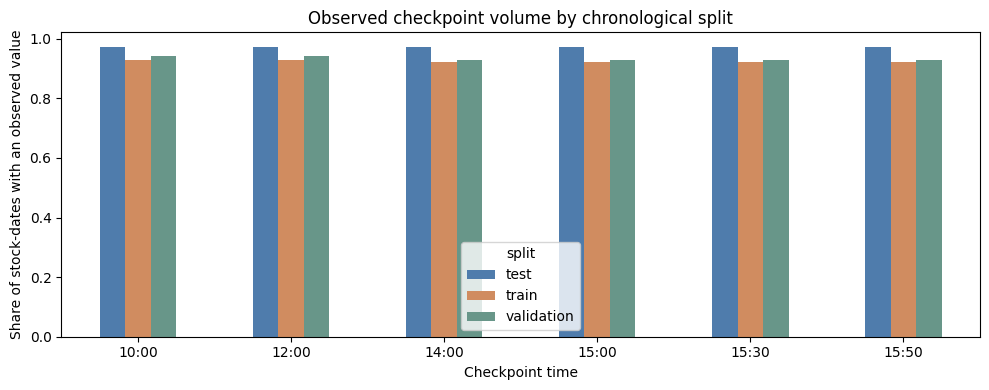


Model features checked: 84


,Feature,test,train,validation,overall
0,feat_momentum_5d,0.124319,0.123940,0.152175,0.128379
1,feat_return_1d,0.109150,0.100291,0.105676,0.102557
2,hist_auction_log_lag1,0.054435,0.091473,0.069834,0.082132
3,hist_1400_log_lag1,0.027181,0.080678,0.072951,0.070834
4,hist_1550_log_lag1,0.027181,0.080678,0.072951,0.070834
5,hist_1530_log_lag1,0.027181,0.080678,0.072951,0.070834
6,hist_1500_log_lag1,0.027181,0.080678,0.072951,0.070834
7,hist_1200_log_lag1,0.027181,0.073721,0.056407,0.063515
8,hist_1000_log_lag1,0.027181,0.073721,0.056407,0.063515
9,hist_auction_log_mean_5,0.030194,0.064208,0.037761,0.054611



Example training-only feature winsorization limits:


,training_window,feature,limits_and_rule
2779,train,hist_auction_log_lag1,lower_0.5%=5.1119876; upper_99.5%=14.807508
2780,train,hist_auction_log_last_valid,lower_0.5%=4.6151204; upper_99.5%=14.853765
2781,train,hist_auction_age_sessions,lower_0.5%=1; upper_99.5%=151
2782,train,hist_auction_log_mean_5,lower_0.5%=5.0135226; upper_99.5%=14.648096
2783,train,hist_auction_log_mean_20,lower_0.5%=4.8675346; upper_99.5%=14.590289
2784,train,hist_auction_log_mean_60,lower_0.5%=4.7621741; upper_99.5%=14.564237
2785,train,hist_auction_log_median_20,lower_0.5%=4.7758389; upper_99.5%=14.56046
2786,train,hist_auction_log_median_60,lower_0.5%=4.6538625; upper_99.5%=14.536281
2787,train,hist_auction_log_std_20,lower_0.5%=0.17403448; upper_99.5%=1.3401151
2788,train,hist_auction_count_5,lower_0.5%=0; upper_99.5%=5


In [3]:
# Summarize chronological splits, target gaps, checkpoint coverage, and model-feature missingness.
split_summary = panel.groupby("sample_split").agg(
    stock_dates=("ticker", "size"),
    stocks=("ticker", "nunique"),
    auction_labels=("auction_volume", "count"),
    first_date=("date", "min"),
    last_date=("date", "max"),
).reset_index()
split_summary["auction_label_coverage"] = split_summary["auction_labels"] / split_summary["stock_dates"]
display(split_summary)

missing_reason_summary = (
    panel.groupby("target_missing_reason", dropna=False).size()
    .rename("stock_dates").reset_index().sort_values("stock_dates", ascending=False)
)
display(missing_reason_summary)

checkpoint_columns = ["cumvol_10:00", "cumvol_12:00", "cumvol_14:00", "cumvol_15:00", "cumvol_15:30", "cumvol_15:50"]
checkpoint_names = ["10:00", "12:00", "14:00", "15:00", "15:30", "15:50"]
checkpoint_rows = []
for split_name, group in panel.groupby("sample_split"):
    for column, label in zip(checkpoint_columns, checkpoint_names):
        available = int(group[column].notna().sum())
        checkpoint_rows.append({
            "split": split_name,
            "checkpoint": label,
            "stock_dates": len(group),
            "observed_checkpoint_values": available,
            "coverage": available / max(len(group), 1),
        })
checkpoint_coverage = pd.DataFrame(checkpoint_rows)
display(checkpoint_coverage)

coverage_pivot = checkpoint_coverage.pivot(index="checkpoint", columns="split", values="coverage").reindex(checkpoint_names)
ax = coverage_pivot.plot(kind="bar", figsize=(10, 4), color=["#4f7cac", "#d08c60", "#689689"])
ax.set_title("Observed checkpoint volume by chronological split")
ax.set_ylabel("Share of stock-dates with an observed value")
ax.set_xlabel("Checkpoint time")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Reuse the pipeline's feature list so diagnostics match the fitted Ridge inputs.
if str(WORKSPACE) not in sys.path:
    sys.path.insert(0, str(WORKSPACE))
from modeling.prepare_nyse_model import _make_preopen_features
panel_header = pd.read_csv(OUTPUT / "nyse_model_panel.csv.gz", compression="gzip", nrows=0)
feature_columns = _make_preopen_features(pd.DataFrame(columns=panel_header.columns))
feature_missing_counts = {}
split_row_counts = {}
for chunk in pd.read_csv(
    OUTPUT / "nyse_model_panel.csv.gz",
    compression="gzip",
    usecols=["sample_split", *feature_columns],
    chunksize=100_000,
    low_memory=False,
):
    for split_name, group in chunk.groupby("sample_split"):
        split_row_counts[split_name] = split_row_counts.get(split_name, 0) + len(group)
        current = group[feature_columns].isna().sum()
        feature_missing_counts[split_name] = feature_missing_counts.get(split_name, pd.Series(0, index=feature_columns)) + current

feature_missingness = pd.DataFrame({
    split_name: counts / split_row_counts[split_name]
    for split_name, counts in feature_missing_counts.items()
})
feature_missingness["overall"] = sum(feature_missing_counts.values()) / sum(split_row_counts.values())
feature_missingness.index.name = "feature"
feature_missingness = feature_missingness.sort_values("overall", ascending=False)
print(f"\nModel features checked: {len(feature_columns)}")
display(feature_missingness.head(20).rename_axis("Feature").reset_index())

winsor_rows = quality.loc[quality["status"].eq("feature_winsor_limits"), ["source_file", "ticker", "detail"]]
print("\nExample training-only feature winsorization limits:")
display(winsor_rows.head(10).rename(columns={"source_file": "training_window", "ticker": "feature", "detail": "limits_and_rule"}))

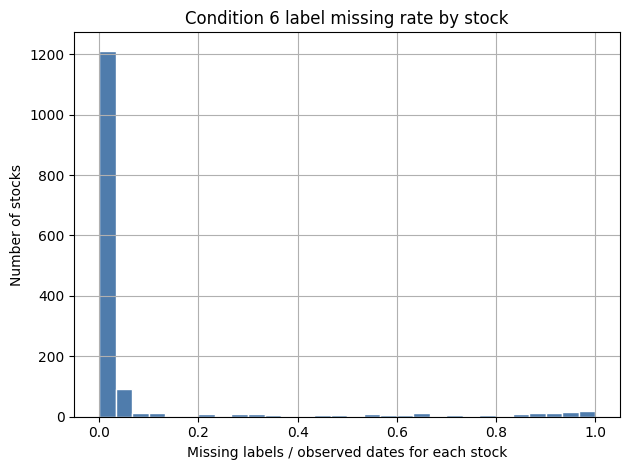

,year,stock_dates,labeled_stock_dates,label_coverage
0,2022,325568,290240,0.891488
1,2023,327098,296644,0.906896
2,2024,340216,313531,0.921565
3,2025,349979,326475,0.932842
4,2026,289962,273276,0.942455


In [4]:
# Figure 1: Yearly stock-date coverage and condition 6 label availability.
year_summary = panel.assign(year=panel["date"].dt.year).groupby("year").agg(
    stock_dates=("ticker", "size"),
    labeled_stock_dates=("auction_volume", "count"),
).reset_index()
year_summary["label_coverage"] = year_summary["labeled_stock_dates"] / year_summary["stock_dates"]

ticker_missing["label_missing_rate"].hist(bins=30, color="#4f7cac", edgecolor="white")
plt.title("Condition 6 label missing rate by stock")
plt.xlabel("Missing labels / observed dates for each stock")
plt.ylabel("Number of stocks")
plt.tight_layout()
plt.show()

display(year_summary)

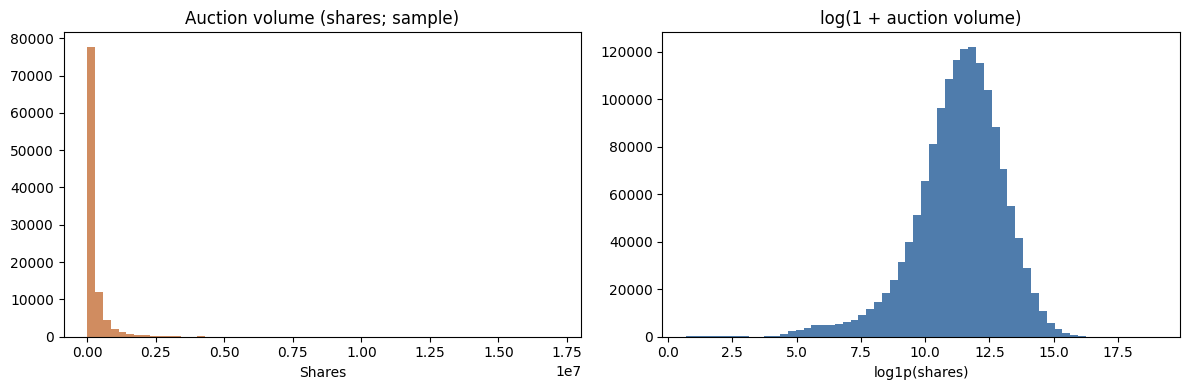

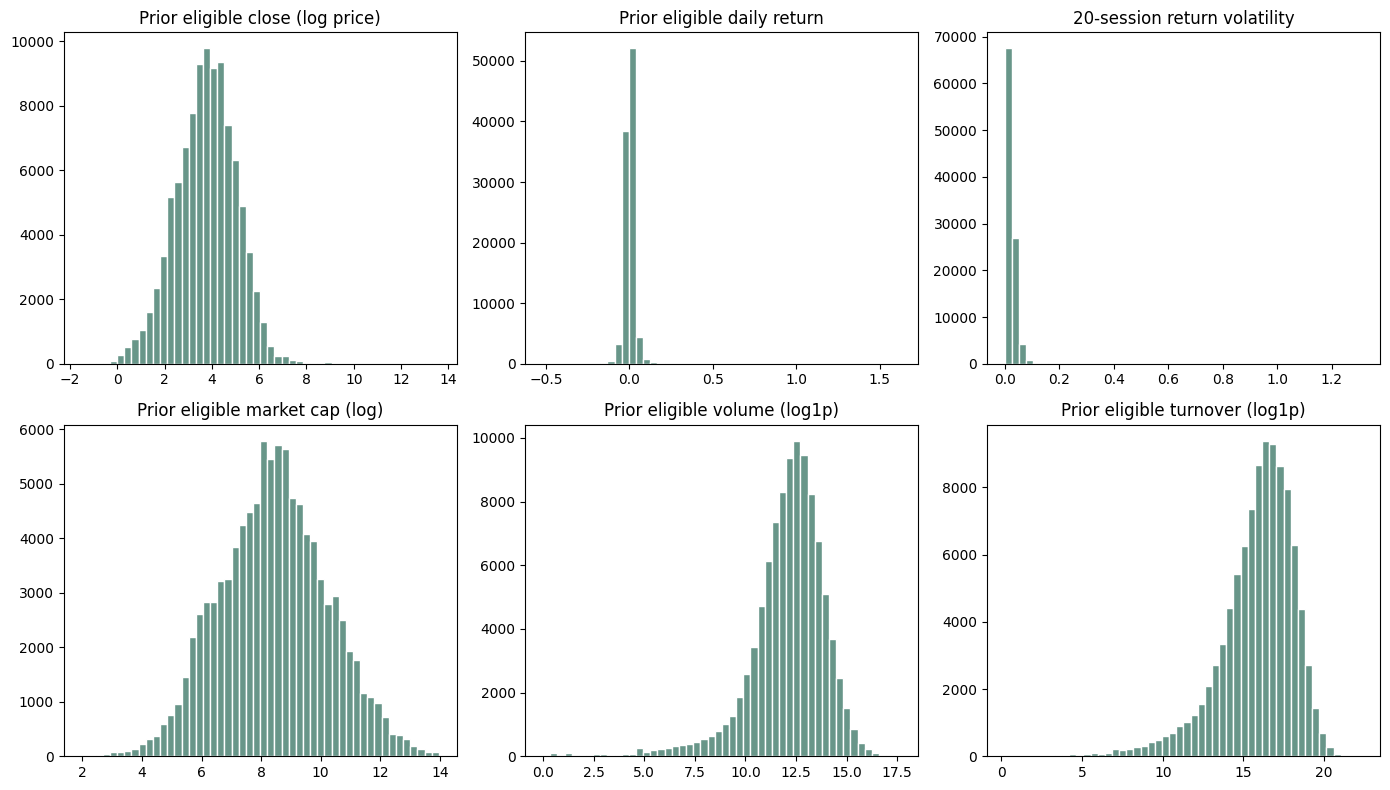

In [5]:
# Figure 2: The auction-volume target is right-skewed; log1p is the model scale.
valid_auction = panel.loc[panel["auction_volume"].gt(0), "auction_volume"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(valid_auction.sample(min(100_000, len(valid_auction)), random_state=7), bins=60, color="#d08c60")
axes[0].set_title("Auction volume (shares; sample)")
axes[0].set_xlabel("Shares")
axes[1].hist(np.log1p(valid_auction), bins=60, color="#4f7cac")
axes[1].set_title("log(1 + auction volume)")
axes[1].set_xlabel("log1p(shares)")
plt.tight_layout()
plt.show()

# Figure 3: Distributions of selected lagged Bloomberg features.
feature_plot = [
    ("feat_px_last_log", "Prior eligible close (log price)"),
    ("feat_return_1d", "Prior eligible daily return"),
    ("feat_volatility_20d", "20-session return volatility"),
    ("feat_market_cap_log", "Prior eligible market cap (log)"),
    ("feat_px_volume_log1p", "Prior eligible volume (log1p)"),
    ("feat_turnover_log1p", "Prior eligible turnover (log1p)"),
]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (col, title) in zip(axes.flat, feature_plot):
    vals = panel[col].dropna()
    if len(vals) > 100_000:
        vals = vals.sample(100_000, random_state=7)
    ax.hist(vals, bins=50, color="#689689", edgecolor="white")
    ax.set_title(title)
plt.tight_layout()
plt.show()

## 预测结果

开盘前先比较一个简单基准（最近一次有效竞价量）、Ridge 和几种树模型；目标截尾 Ridge 只作为敏感性结果。固定切分下，所有方法在同一批测试股票日上比较。树模型最多使用 25 万条训练股票日。

另外增加了按季度重新训练的扩展窗口：每季开始时，用此前所有有标签的股票日重新拟合模型，再预测这一季。这样可以检查模型随着历史数据增加，结果是否改变。盘中部分仍比较三种 Ridge 更新方法：历史比例、当天真实 checkpoint，以及 checkpoint 预测误差修正。

,model_label,n,training_n,coverage,mae_log,rmse_log,mae_shares,rmse_shares
0,Last observed auction,249502,NaN,1.0,0.360783,0.498745,133871.16,555780.64
1,Ridge,249502,NaN,1.0,0.286866,0.395975,106424.53,462951.14
3,XGBoost,249502,250000.0,1.0,0.282413,0.390265,100767.18,434308.52
4,LightGBM,249502,250000.0,1.0,0.282490,0.390358,101142.91,436196.82
5,CatBoost,249502,250000.0,1.0,0.283579,0.391260,101515.22,438793.36
6,HistGradientBoosting,249502,250000.0,1.0,0.282767,0.390637,101145.48,436735.61
2,Ridge (target sensitivity),249502,NaN,1.0,0.286792,0.396141,106481.81,465074.62


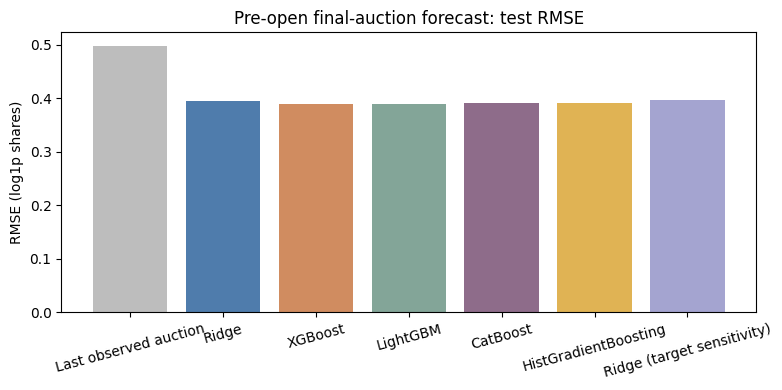

In [6]:
# Figure 4: Pre-open final-auction performance on identical test stock-dates.
preopen_metrics = metrics[(metrics["split"] == "test_common") & (metrics["target"] == "auction")].copy()
model_order = [
    "Last_valid_auction", "Ridge_preopen", "XGBoost_preopen", "LightGBM_preopen",
    "CatBoost_preopen", "HistGradientBoosting_preopen", "Ridge_target_winsor_sensitivity",
]
model_labels = {
    "Last_valid_auction": "Last observed auction",
    "Ridge_preopen": "Ridge",
    "XGBoost_preopen": "XGBoost",
    "LightGBM_preopen": "LightGBM",
    "CatBoost_preopen": "CatBoost",
    "HistGradientBoosting_preopen": "HistGradientBoosting",
    "Ridge_target_winsor_sensitivity": "Ridge (target sensitivity)",
}
preopen_metrics["model_label"] = preopen_metrics["model"].map(model_labels)
preopen_metrics["model"] = pd.Categorical(preopen_metrics["model"], categories=model_order, ordered=True)
preopen_metrics = preopen_metrics.sort_values("model")
display(preopen_metrics[["model_label", "n", "training_n", "coverage", "mae_log", "rmse_log", "mae_shares", "rmse_shares"]])

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(preopen_metrics["model_label"], preopen_metrics["rmse_log"], color=["#bdbdbd", "#4f7cac", "#d08c60", "#83a598", "#8e6c8a", "#e0b354", "#a4a4d0"][:len(preopen_metrics)])
ax.set_title("Pre-open final-auction forecast: test RMSE")
ax.set_ylabel("RMSE (log1p shares)")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

,Model,Training approach,Test stock-days,Training rows,Refits,RMSE log,MAE shares
0,Last observed auction,One fit before test,249502,—,0,0.498745,133871.16
1,Last observed auction,Quarterly expanding,249502,—,0,0.498745,133871.16
2,Ridge,One fit before test,249502,—,1,0.395975,106424.53
3,Ridge,Quarterly expanding,249502,"1,250,585–1,482,742",4,0.399929,105723.04
4,XGBoost,One fit before test,249502,"250,000",1,0.390265,100767.18
5,XGBoost,Quarterly expanding,249502,"250,000–250,000",4,0.389555,100425.37
6,LightGBM,One fit before test,249502,"250,000",1,0.390358,101142.91
7,LightGBM,Quarterly expanding,249502,"250,000–250,000",4,0.389753,100827.65
8,CatBoost,One fit before test,249502,"250,000",1,0.391260,101515.22
9,CatBoost,Quarterly expanding,249502,"250,000–250,000",4,0.390686,100777.08


Both approaches score the same number of test stock-days: True


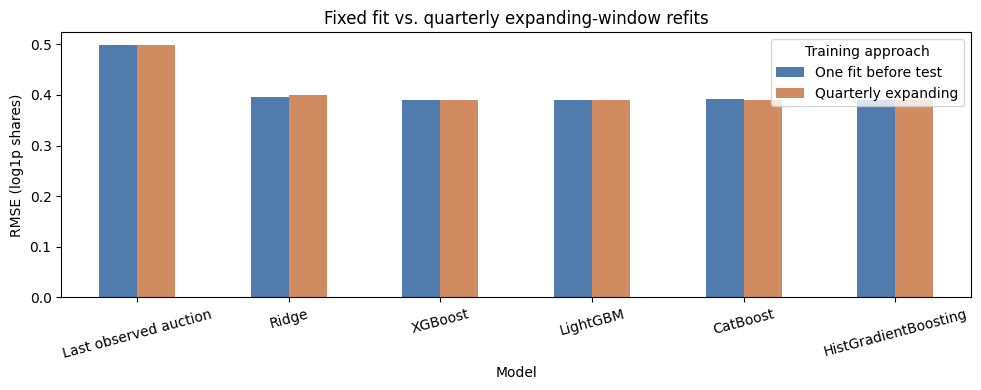

In [7]:
# Figure 5: Compare the fixed holdout fit with quarterly expanding-window refits.
fixed_lookup = {
    "Last observed auction": "Last_valid_auction",
    "Ridge": "Ridge_preopen",
    "XGBoost": "XGBoost_preopen",
    "LightGBM": "LightGBM_preopen",
    "CatBoost": "CatBoost_preopen",
    "HistGradientBoosting": "HistGradientBoosting_preopen",
}
walk_lookup = {
    "Last observed auction": "Last_valid_auction",
    "Ridge": "Ridge_quarterly_expanding",
    "XGBoost": "XGBoost_quarterly_expanding",
    "LightGBM": "LightGBM_quarterly_expanding",
    "CatBoost": "CatBoost_quarterly_expanding",
    "HistGradientBoosting": "HistGradientBoosting_quarterly_expanding",
}
fixed_rows = metrics[(metrics["split"] == "test_common") & (metrics["target"] == "auction")].set_index("model")
walk_rows = metrics[(metrics["split"] == "walk_forward_common") & (metrics["target"] == "auction")].set_index("model")
comparison_rows = []
for label, fixed_name in fixed_lookup.items():
    walk_name = walk_lookup[label]
    if fixed_name in fixed_rows.index:
        row = fixed_rows.loc[fixed_name]
        fixed_training_n = row.get("training_n", np.nan)
        fixed_training_display = f"{int(fixed_training_n):,}" if pd.notna(fixed_training_n) else "—"
        fixed_refits = 0 if label == "Last observed auction" else 1
        comparison_rows.append({"Model": label, "Training approach": "One fit before test", "Test stock-days": int(row["n"]), "Training rows": fixed_training_display, "Refits": fixed_refits, "RMSE log": row["rmse_log"], "MAE shares": row["mae_shares"]})
    if walk_name in walk_rows.index:
        row = walk_rows.loc[walk_name]
        minimum_rows = row.get("training_n_min", np.nan)
        maximum_rows = row.get("training_n_max", np.nan)
        if pd.isna(minimum_rows) or pd.isna(maximum_rows):
            training_rows = "—"
            refit_count = 0
        else:
            training_rows = f"{int(minimum_rows):,}–{int(maximum_rows):,}"
            refit_count = int(row.get("fold_count", 0))
        comparison_rows.append({"Model": label, "Training approach": "Quarterly expanding", "Test stock-days": int(row["n"]), "Training rows": training_rows, "Refits": refit_count, "RMSE log": row["rmse_log"], "MAE shares": row["mae_shares"]})
comparison = pd.DataFrame(comparison_rows)
display(comparison)
if not comparison.empty:
    row_counts = comparison.groupby("Training approach")["Test stock-days"].unique()
    same_test_count = len(row_counts) == 2 and len(row_counts.iloc[0]) == len(row_counts.iloc[1]) == 1 and row_counts.iloc[0][0] == row_counts.iloc[1][0]
    print("Both approaches score the same number of test stock-days:", same_test_count)
    chart = comparison.pivot(index="Model", columns="Training approach", values="RMSE log")
    chart = chart.reindex(list(fixed_lookup))
    ax = chart.plot(kind="bar", figsize=(10, 4), color=["#4f7cac", "#d08c60"])
    ax.set_title("Fixed fit vs. quarterly expanding-window refits")
    ax.set_ylabel("RMSE (log1p shares)")
    ax.set_xlabel("Model")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

## 相似股票分组：K-means + Ridge

这里检验一个想法：过去成交模式相近的股票，是否可以互相提供信息。每个测试季度开始时，先只用这个季度之前的资料给股票分组，再把组别加入 Ridge 输入。分组资料包括过去竞价量和六个 checkpoint 的水平、竞价量与盘中量的比例、市值和波动率。候选组数为 2–8，按轮廓系数选择。

组别在该季度内保持不变；普通季度 Ridge 和 K-means Ridge 使用同一批测试股票日。组别编号只是类别标签，例如 C0、C1 本身没有高低含义。

,model,n,fold_count,training_n_min,training_n_max,rmse_log,mae_shares,rmse_shares
8,Ridge_quarterly_expanding,249502,4.0,1250585.0,1482742.0,0.399929,105723.04,458036.24
9,Ridge_KMeans_quarterly_expanding,249502,4.0,1250585.0,1482742.0,0.399801,105799.16,457939.79


,source_file,date,rows,detail
2958,KMeans,2026-01-28 00:00:00,1445,profile_available_through=2026-01-27; profile_...
3048,KMeans,2026-04-01 00:00:00,1462,profile_available_through=2026-03-31; profile_...
3138,KMeans,2026-07-01 00:00:00,1490,profile_available_through=2026-06-30; profile_...
3228,KMeans,2026-10-01 00:00:00,1504,profile_available_through=2026-09-30; profile_...


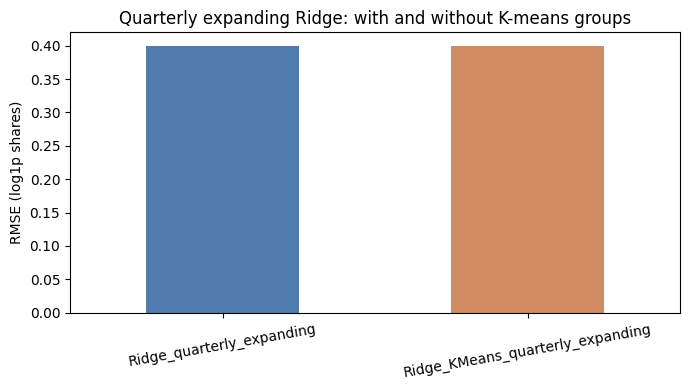

,quarter_cluster,test_stock_dates
0,2026Q3_C1,64134
1,2026Q2_C1,53680
2,2026Q1_C1,37338
3,2026Q2_C0,35441
4,2026Q3_C0,29736
5,2026Q1_C0,23352
6,2026Q4_C0,12621
7,2026Q4_C1,5424
8,2026Q2_unknown,878
9,2026Q3_unknown,624


In [8]:
# Compare ordinary quarterly Ridge with the K-means-augmented Ridge on the same test rows.
quarterly_models = ["Ridge_quarterly_expanding", "Ridge_KMeans_quarterly_expanding"]
kmeans_comparison = metrics[
    (metrics["split"] == "walk_forward_common")
    & (metrics["target"] == "auction")
    & metrics["model"].isin(quarterly_models)
].copy()
display(kmeans_comparison[["model", "n", "fold_count", "training_n_min", "training_n_max", "rmse_log", "mae_shares", "rmse_shares"]])

cluster_folds = quality.loc[quality["status"].eq("quarterly_clusters_fitted"), ["source_file", "date", "rows", "detail"]].copy()
display(cluster_folds)

if not kmeans_comparison.empty:
    ax = kmeans_comparison.set_index("model")["rmse_log"].plot(kind="bar", figsize=(7, 4), color=["#4f7cac", "#d08c60"])
    ax.set_title("Quarterly expanding Ridge: with and without K-means groups")
    ax.set_ylabel("RMSE (log1p shares)")
    ax.set_xlabel("")
    plt.xticks(rotation=10)
    plt.tight_layout()
    plt.show()

if "quarterly_kmeans_cluster" in predictions.columns:
    cluster_counts = predictions["quarterly_kmeans_cluster"].value_counts(dropna=False).rename_axis("quarter_cluster").reset_index(name="test_stock_dates")
    display(cluster_counts.head(20))

,checkpoint,model_label,n,mae_log,rmse_log,mae_shares,rmse_shares
26,10:00,Historical ratio,249384,0.524502,0.719787,186612.53,695511.17
27,10:00,Actual checkpoint update,249384,0.281315,0.389482,104763.69,461348.90
28,10:00,Forecast-error correction,249384,0.281293,0.389398,104480.87,460339.89
29,12:00,Historical ratio,249411,0.431115,0.597984,153277.56,1224319.70
30,12:00,Actual checkpoint update,249411,0.278198,0.386686,103758.43,459049.35
31,12:00,Forecast-error correction,249411,0.277620,0.386273,103268.49,458193.32
32,14:00,Historical ratio,249433,0.399009,0.557248,142481.89,1230989.30
33,14:00,Actual checkpoint update,249433,0.275526,0.384331,103144.07,458308.50
34,14:00,Forecast-error correction,249433,0.275190,0.384006,102514.90,456308.89
35,15:00,Historical ratio,249433,0.385500,0.540051,137780.70,1226405.10


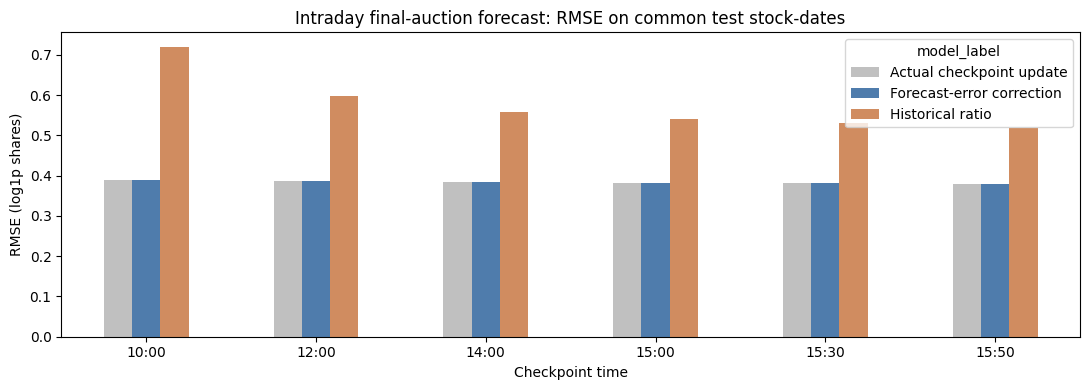

In [9]:
# Figure 6: Intraday methods at six checkpoints, scored on common stock-dates.
cutoff_labels = {"1000": "10:00", "1200": "12:00", "1400": "14:00", "1500": "15:00", "1530": "15:30", "1550": "15:50"}
model_labels = {"naive": "Historical ratio", "direct": "Actual checkpoint update", "error_correction": "Forecast-error correction"}
intraday_rows = metrics[
    (metrics["split"] == "test_common") & metrics["target"].str.startswith("auction_at_")
].copy()
intraday_rows["checkpoint"] = intraday_rows["target"].str.rsplit("_", n=1).str[-1].map(cutoff_labels)
intraday_rows["model_label"] = intraday_rows["model"].map(model_labels)
display(intraday_rows[["checkpoint", "model_label", "n", "mae_log", "rmse_log", "mae_shares", "rmse_shares"]])

pivot = intraday_rows.pivot(index="checkpoint", columns="model_label", values="rmse_log").reindex(list(cutoff_labels.values()))
ax = pivot.plot(kind="bar", figsize=(11, 4), color=["#c0c0c0", "#4f7cac", "#d08c60"])
ax.set_title("Intraday final-auction forecast: RMSE on common test stock-dates")
ax.set_ylabel("RMSE (log1p shares)")
ax.set_xlabel("Checkpoint time")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

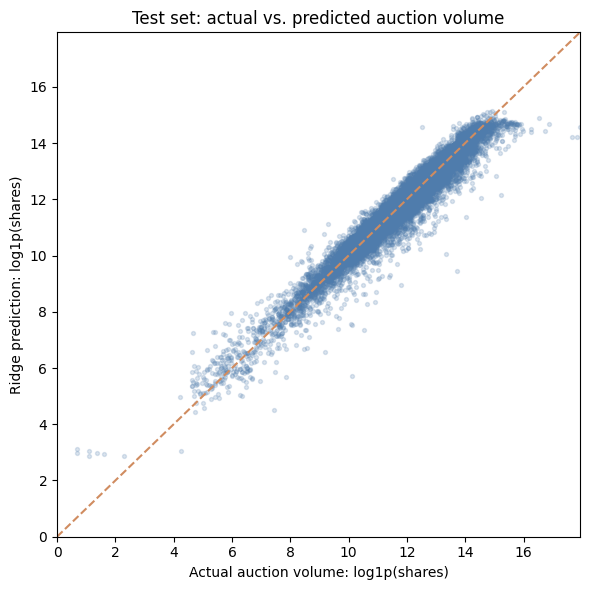

In [10]:
# Figure 7: Actual vs. Ridge test predictions on the log1p scale.
scatter = predictions.dropna(subset=["actual_auction_volume", "auction_ridge"]).copy()
if len(scatter) > 15_000:
    scatter = scatter.sample(15_000, random_state=7)
actual_log = np.log1p(scatter["actual_auction_volume"])
pred_log = np.log1p(scatter["auction_ridge"])
lims = [0, max(float(actual_log.max()), float(pred_log.max()))]
plt.figure(figsize=(6, 6))
plt.scatter(actual_log, pred_log, s=8, alpha=.2, color="#4f7cac")
plt.plot(lims, lims, linestyle="--", color="#d08c60")
plt.xlim(lims)
plt.ylim(lims)
plt.xlabel("Actual auction volume: log1p(shares)")
plt.ylabel("Ridge prediction: log1p(shares)")
plt.title("Test set: actual vs. predicted auction volume")
plt.tight_layout()
plt.show()

## 如何理解结果

- 主标签来自 WRDS TAQ 的 `condition 6`。没有对应成交记录时保留缺失，不当作零成交。
- 收盘价和市值最多沿用此前 5 个合格交易日内最近的有效值；成交量和成交额缺失时用此前 5 个合格交易日的中位数（至少 3 个有效值）。收益率和波动率只由真实历史价格计算，不补造收益；为避免严格排除事件日后窗口过于稀疏，5 日动量需要 4 个有效收益；20 日动量和波动率需要 15 个；60 日波动率需要 45 个。当天 checkpoint 只用于对应时点之后的更新。
- 特征截尾边界、缺失值填补和标准化只根据训练窗口估计。模型预测 `log1p(成交股数)`，评估时也保留原始标签。目标截尾 Ridge 只作敏感性比较。
- 固定切分在测试期开始前拟合一次。扩展窗口每季度重拟合一次，训练数据只包含该季度开始前已经观测到的标签；它不是每天重训。树模型每次从当时可用的训练数据中最多抽取 25 万条。
- 指数重构实施日从建模样本和历史滚动特征中排除。`market_feature_date` 记录价格类特征实际取值的日期。
- 当前 Bloomberg 文件没有记录历史拆股调整设置，因此本版使用文件里已有的数值，不能确认拆股口径已按当时信息还原。股票名单也是当前 Bloomberg 分组，不是逐日历史成分股。
- K-means 每季开始时只用该季度之前的股票特征分组，并与普通季度 Ridge 在相同测试股票日上比较。

In [11]:
best_preopen = preopen_metrics.sort_values("rmse_log").head(1)
best_intraday = intraday_rows.sort_values("rmse_log").groupby("checkpoint", as_index=False).first()
best_walkforward = metrics[(metrics["split"] == "walk_forward_common") & (metrics["target"] == "auction")].sort_values("rmse_log").head(1)
print("Best fixed-fit pre-open method by log RMSE:")
display(best_preopen[["model_label", "n", "rmse_log", "mae_shares", "rmse_shares"]])
print("Best quarterly expanding-window method by log RMSE:")
display(best_walkforward[["model", "n", "fold_count", "training_n_min", "training_n_max", "rmse_log", "mae_shares"]])
print("Best method at each checkpoint by log RMSE:")
display(best_intraday[["checkpoint", "model_label", "n", "rmse_log", "mae_shares"]])

Best fixed-fit pre-open method by log RMSE:


,model_label,n,rmse_log,mae_shares,rmse_shares
3,XGBoost,249502,0.390265,100767.18,434308.52


Best quarterly expanding-window method by log RMSE:


,model,n,fold_count,training_n_min,training_n_max,rmse_log,mae_shares
10,XGBoost_quarterly_expanding,249502,4.0,250000.0,250000.0,0.389555,100425.37


Best method at each checkpoint by log RMSE:


,checkpoint,model_label,n,rmse_log,mae_shares
0,10:00,Forecast-error correction,249384,0.389398,104480.87
1,12:00,Forecast-error correction,249411,0.386273,103268.49
2,14:00,Forecast-error correction,249433,0.384006,102514.90
3,15:00,Forecast-error correction,249433,0.382398,102005.92
4,15:30,Forecast-error correction,249433,0.381315,101641.00
5,15:50,Forecast-error correction,249433,0.379673,101171.94
